# Laboratorio 3 - La tarea de clasificación

Integrantes: Jose Fonseca, Daniel Galindo

Ruta Alpes quiere identificar, para dos tipos de cupón (Cafetería y Restaurante(<20)), en qué escenarios de
conducción un conductor tiene mayor probabilidad de aceptarlo. Cada fila del conjunto de datos describe un escenario
(destino, hora, clima, acompañantes, distancia al establecimiento) junto con el perfil y los hábitos de consumo del
conductor, y la columna `acepta_cupon` indica si aceptó el cupón ofrecido.

## Exploración de datos

El primer paso del ciclo de machine learning es explorar el conjunto de datos para entender su estructura y detectar
problemas de calidad que deban resolverse antes de construir los modelos. Para empezar se cargan los datos de
entrenamiento, los datos de prueba sin etiquetar y el diccionario de datos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, precision_recall_fscore_support

SEED = 42
CUPONES = ["Cafetería", "Restaurante(<20)"]
COLOR = {"Cafetería": "#2a78d6", "Restaurante(<20)": "#eb6834"}

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

datos = pd.read_excel("data/Lab3_Datos.xlsx")
prueba = pd.read_excel("data/Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("data/Lab3_diccionario_Datos.xlsx")
print("datos:", datos.shape, "| prueba (sin etiqueta):", prueba.shape)
datos.head()

datos: (12664, 26) | prueba (sin etiqueta): (20, 25)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


El conjunto de entrenamiento tiene 12.664 escenarios y 26 columnas, de las cuales 25 son variables de entrada y una es
la variable objetivo. Los datos de prueba tienen 20 escenarios con las mismas variables de entrada y sin etiqueta.

### Tipos estadísticos de las columnas

A partir del diccionario de datos se identifica el tipo estadístico de cada columna, lo cual define más adelante cómo
debe codificarse.

In [2]:
print(datos.dtypes.value_counts().to_string())
diccionario[["Variable", "Tipo"]]

str      25
int64     1


,Variable,Tipo
0,destino,Categórica nominal
1,acompanante,Categórica nominal
2,clima,Categórica nominal
3,temperatura,Numérica entero
4,hora,Categórica ordinal
5,cupon,Categórica nominal
6,vigencia_cupon,Categórica nominal
7,genero,Categórica nominal
8,edad,Categórica ordinal
9,estado_civil,Categórica nominal


Todas las columnas están almacenadas como texto excepto `temperatura`. Esto incluye a las variables ordinales
(`hora`, `edad`, `educacion`, `ingreso` y las cinco `frecuencia_*`), cuyo orden se pierde si se tratan como texto. Por
lo tanto, en la preparación será necesario codificarlas respetando el orden que indica el diccionario. Las demás
variables categóricas son nominales y las de tipo Sí/No son binarias.

### Evaluación de las 4 dimensiones de calidad de datos

Una vez identificados los tipos de las columnas se revisan las cuatro dimensiones de calidad: completitud (valores
nulos), unicidad (registros duplicados), consistencia (formatos y relaciones coherentes entre columnas) y validez
(valores dentro de los rangos esperados). Como los modelos se construyen por separado para cada cupón, los resultados
se reportan también para cada subconjunto.

#### Completitud

In [3]:
faltantes = pd.DataFrame({"faltantes": datos.isna().sum(), "%": (100 * datos.isna().mean()).round(2)})
faltantes = faltantes[faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    faltantes[f"% en {cupon}"] = (100 * sub[faltantes.index].isna().mean()).round(2)
faltantes

,faltantes,%,% en Cafetería,% en Restaurante(<20)
vehiculo,12556,99.15,99.07,99.10
frecuencia_cafeteria,217,1.71,1.81,1.69
frecuencia_restaurante_20_a_50,189,1.49,1.38,1.55
frecuencia_comida_para_llevar,151,1.19,1.43,1.22
frecuencia_restaurante_menos_20,130,1.03,1.25,0.97
frecuencia_bar,107,0.84,0.93,0.83


La columna `vehiculo` está vacía en el 99,1 % de los escenarios: solo 108 de 12.664 registros tienen un valor, por lo
que no es posible imputarla sin inventar casi toda la columna. Por otro lado, las cinco variables de frecuencia de
consumo tienen entre 0,8 % y 1,8 % de valores nulos, con proporciones muy parecidas en los dos subconjuntos. Al ser
pocos, estos valores sí pueden completarse en la preparación sin alterar la distribución de los datos. El resto de
columnas está completo.

#### Unicidad

In [4]:
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    x = sub.drop(columns="acepta_cupon")
    print(f"{cupon}: {sub.duplicated().sum()} duplicados exactos | "
          f"{x.duplicated(keep=False).sum() - sub.duplicated(keep=False).sum()} filas con las mismas variables "
          f"y distinta etiqueta")

Cafetería: 7 duplicados exactos | 8 filas con las mismas variables y distinta etiqueta
Restaurante(<20): 7 duplicados exactos | 6 filas con las mismas variables y distinta etiqueta


Cada subconjunto tiene 7 filas duplicadas exactamente, es decir, con las mismas variables y la misma etiqueta. Si una
copia queda en el conjunto de entrenamiento y otra en el de prueba, el modelo se evalúa con un escenario que ya vio,
por lo que deben eliminarse. Además, hay unas pocas filas con las mismas variables pero distinta etiqueta (8 en
Cafetería y 6 en Restaurante). Estas no se consideran un error, ya que dos conductores con el mismo perfil y en el mismo
escenario pueden tomar decisiones distintas; reflejan el ruido propio de la variable objetivo.

#### Consistencia

In [5]:
print("Columnas con menos de 3 valores distintos:")
print(datos.nunique().loc[lambda s: s < 3].to_string(), "\n")
print(pd.crosstab(datos["misma_direccion"], datos["direccion_opuesta"]), "\n")
print(pd.crosstab(datos["tiempo_cupon_mayor_15min"], datos["tiempo_cupon_mayor_25min"]), "\n")
print(pd.crosstab(datos["clima"], datos["temperatura"]))

Columnas con menos de 3 valores distintos:
vigencia_cupon              2
genero                      2
tiene_hijos                 2
tiempo_cupon_mayor_5min     1
tiempo_cupon_mayor_15min    2
tiempo_cupon_mayor_25min    2
misma_direccion             2
direccion_opuesta           2
acepta_cupon                2 

direccion_opuesta    No    Sí
misma_direccion              
No                    0  9944
Sí                 2720     0 

tiempo_cupon_mayor_25min    No    Sí
tiempo_cupon_mayor_15min            
No                        5551     0
Sí                        5602  1511 

temperatura    30    55    80
clima                        
Lluvioso        0  1208     0
Nevado       1404     0     0
Soleado       911  2628  6513


La variable `tiempo_cupon_mayor_5min` toma siempre el valor Sí, de modo que no aporta información para distinguir
entre escenarios. La variable `direccion_opuesta` es exactamente el complemento de `misma_direccion`, como muestra la
tabla cruzada, por lo que es redundante y basta con conservar una de las dos. En cambio, `tiempo_cupon_mayor_15min` y
`tiempo_cupon_mayor_25min` están anidadas pero no son redundantes, ya que juntas describen tres niveles de distancia
(hasta 15, entre 15 y 25 y más de 25 minutos). Algo similar ocurre con `clima` y `temperatura`: el clima lluvioso
siempre corresponde a 55 °F y el nevado a 30 °F, pero el soleado toma los tres valores, así que ambas aportan
información.

In [6]:
print(pd.crosstab(datos["destino"], datos["hora"]), "\n")
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    n = ((sub["acompanante"] == "Hijo(s)") & (sub["tiene_hijos"] == "No")).sum()
    print(f"{cupon}: {n} escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'")

hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0        1113          0       2120          0
Sin lugar urgente        2271         890       2005       1104          0
Trabajo                     0           0          0          0       3161 

Cafetería: 4 escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'
Restaurante(<20): 3 escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'


El destino y la hora están muy ligados por el diseño de la encuesta (por ejemplo, el destino Trabajo solo aparece a
las 7:00 a.m.), lo que hará difícil separar el efecto de una variable del de la otra. También se encontraron unos
pocos escenarios (4 en Cafetería y 3 en Restaurante) en los que el conductor va con sus hijos pero reporta no tenerlos.
Puede tratarse de un error de registro o de niños que no son propios; al ser tan pocos casos, se conservan.

#### Validez

In [7]:
for col in datos.columns.drop(["ocupacion", "acepta_cupon"]):
    print(f"{col}: {sorted(datos[col].dropna().astype(str).unique())}")

destino: ['Casa', 'Sin lugar urgente', 'Trabajo']
acompanante: ['Amigo(s)', 'Hijo(s)', 'Pareja', 'Solo']
clima: ['Lluvioso', 'Nevado', 'Soleado']
temperatura: ['30', '55', '80']
hora: ['10:00 a.m.', '10:00 p.m.', '2:00 p.m.', '6:00 p.m.', '7:00 a.m.']
cupon: ['Bar', 'Cafetería', 'Comida para llevar', 'Restaurante(20-50)', 'Restaurante(<20)']
vigencia_cupon: ['1 día', '2 horas']
genero: ['Femenino', 'Masculino']
edad: ['21', '26', '31', '36', '41', '46', '50 o más', 'menor de 21']
estado_civil: ['Casado(a)', 'Divorciado(a)', 'Soltero(a)', 'Unión libre', 'Viudo(a)']
tiene_hijos: ['No', 'Sí']
educacion: ['Bachillerato completo', 'Bachillerato incompleto', 'Estudios universitarios sin título', 'Posgrado (Maestría o Doctorado)', 'Pregrado', 'Técnico/Tecnólogo']
ingreso: ['$100.000 o más', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999', '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999', 'Menos de $12.500']
vehiculo: ['Camioneta tipo crossover',

Todos los valores coinciden con los descritos en el diccionario de datos y no se encontraron formatos inconsistentes,
como mayúsculas o espacios distintos para una misma categoría. La `temperatura` solo toma los tres valores esperados
(30, 55 y 80). La única excepción de formato es una categoría informal de `vehiculo` ("Carro muy viejo para instalarle
Onstar :D"), que no tiene efecto porque esa columna se eliminará. Por último, `ocupacion` tiene 25 categorías, varias
con muy pocos casos, lo que se tendrá en cuenta al codificarla.

### Distribución de la variable objetivo en cada subconjunto

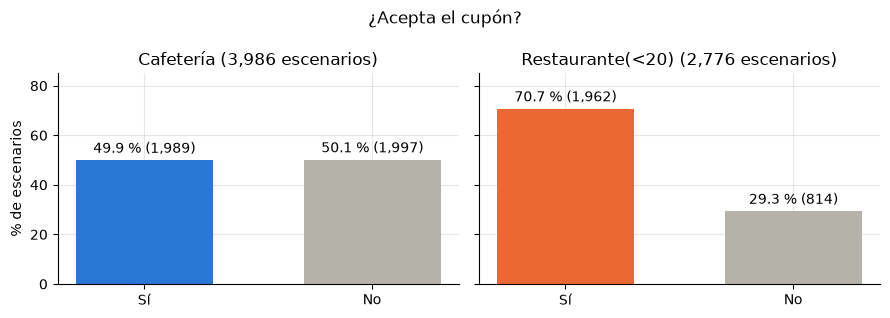

acepta_cupon,Sí,No,total,% Sí
Cafetería,1989,1997,3986,49.9
Restaurante(<20),1962,814,2776,70.7


In [8]:
subconjuntos = {c: datos[datos["cupon"] == c].copy() for c in CUPONES}
distribucion = pd.DataFrame({c: s["acepta_cupon"].value_counts() for c, s in subconjuntos.items()}).T[["Sí", "No"]]
distribucion["total"] = distribucion.sum(axis=1)
distribucion["% Sí"] = (100 * distribucion["Sí"] / distribucion["total"]).round(1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (cupon, fila) in zip(axes, distribucion.iterrows()):
    pct = 100 * fila[["Sí", "No"]] / fila["total"]
    barras = ax.bar(pct.index, pct.values, color=[COLOR[cupon], "#b4b2a9"], width=0.6)
    ax.bar_label(barras, labels=[f"{v:.1f} % ({int(n):,})" for v, n in zip(pct, fila[["Sí", "No"]])], padding=3)
    ax.set_title(f"{cupon} ({int(fila['total']):,} escenarios)")
    ax.set_ylim(0, 85)
axes[0].set_ylabel("% de escenarios")
fig.suptitle("¿Acepta el cupón?")
plt.tight_layout()
plt.show()
distribucion

El subconjunto de Cafetería (3.986 escenarios) está balanceado, con 49,9 % de aceptaciones y 50,1 % de rechazos. En
cambio, el de Restaurante(<20) (2.776 escenarios) está desbalanceado: el 70,7 % de los conductores acepta el cupón y
solo el 29,3 % lo rechaza, de modo que la clase minoritaria es No.

Este desbalance tiene dos consecuencias. La primera es que en Restaurante un modelo que siempre prediga Sí ya
alcanzaría una exactitud de 70,7 %, por lo que la accuracy no es una buena métrica y se deben revisar la precisión, el
recall y el F1-score de cada clase, en especial el recall de la clase No. La segunda es que la división en
entrenamiento y prueba y la validación cruzada deben ser estratificadas, para que ambas clases conserven su proporción
en cada partición.

### Visualización de la aceptación según el contexto

Para tener una primera idea de qué variables podrían ser informativas, se compara la proporción de aceptación según
los valores de algunas variables del contexto y del hábito de consumo del conductor.

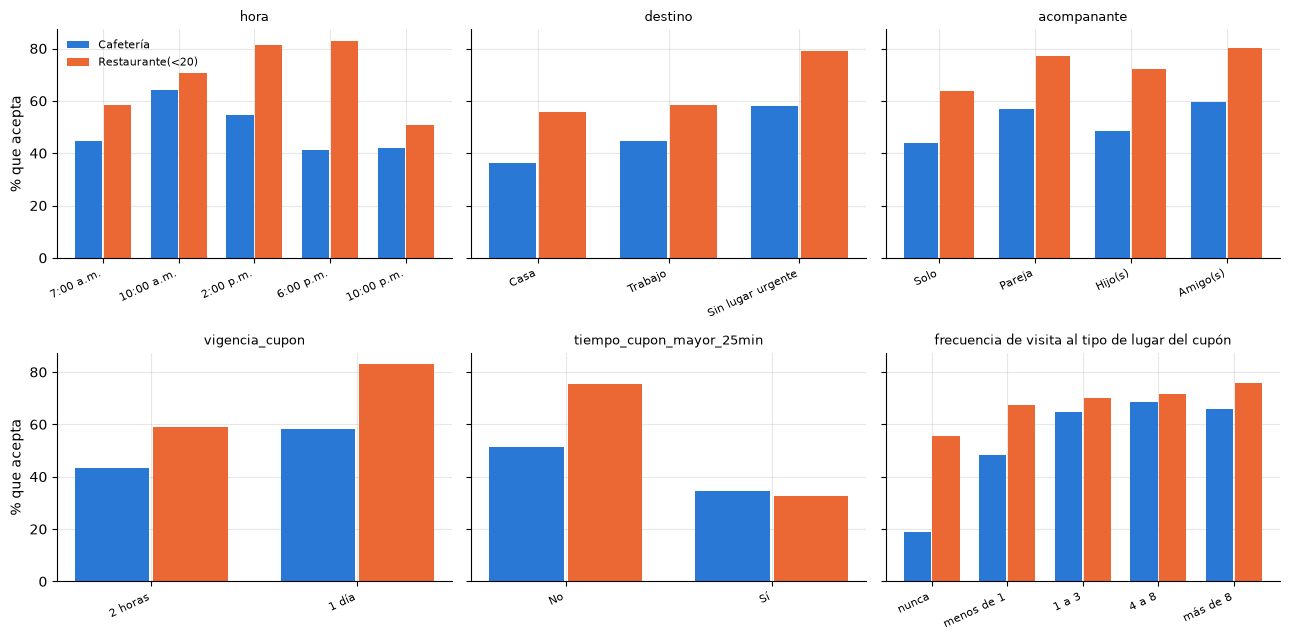

In [9]:
ORDEN_HORA = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
ORDEN_FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
GRAFICOS = [
    ("hora", ORDEN_HORA),
    ("destino", ["Casa", "Trabajo", "Sin lugar urgente"]),
    ("acompanante", ["Solo", "Pareja", "Hijo(s)", "Amigo(s)"]),
    ("vigencia_cupon", ["2 horas", "1 día"]),
    ("tiempo_cupon_mayor_25min", ["No", "Sí"]),
    ("frecuencia propia", ORDEN_FRECUENCIA),
]
FRECUENCIA_PROPIA = {"Cafetería": "frecuencia_cafeteria", "Restaurante(<20)": "frecuencia_restaurante_menos_20"}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (variable, orden) in zip(axes.flat, GRAFICOS):
    x = np.arange(len(orden))
    for k, (cupon, sub) in enumerate(subconjuntos.items()):
        col = FRECUENCIA_PROPIA[cupon] if variable == "frecuencia propia" else variable
        tasa = sub.groupby(col)["acepta_cupon"].apply(lambda s: (s == "Sí").mean()).reindex(orden)
        ax.bar(x + (k - 0.5) * 0.38, 100 * tasa.values, width=0.36, color=COLOR[cupon], label=cupon)
    ax.set_xticks(x, orden, rotation=25, ha="right", fontsize=8)
    ax.set_title(variable if variable != "frecuencia propia" else "frecuencia de visita al tipo de lugar del cupón",
                 fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("% que acepta")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

La variable que muestra la mayor diferencia es el hábito de consumo: en Cafetería, los conductores que nunca van a una
cafetería aceptan el cupón solo el 19 % de las veces, frente a un 65 %–69 % de quienes van al menos una vez al mes.
En Restaurante este efecto también existe, aunque es menor. La distancia también influye de forma clara, ya que cuando
el establecimiento está a más de 25 minutos la aceptación baja de 51 % a 35 % en Cafetería y de 75 % a 33 % en
Restaurante. Además, los cupones con vigencia de un día se aceptan más que los de dos horas, y la aceptación es mayor
cuando el conductor no tiene un lugar urgente al que llegar. En cuanto a la hora, Cafetería se acepta más a las
10:00 a.m. y Restaurante a las 2:00 p.m. y 6:00 p.m., lo que es coherente con los horarios de cada tipo de lugar. Por
el contrario, las variables demográficas como el género muestran diferencias mucho menores (49 % frente a 51 % en
Cafetería), lo cual será relevante para el análisis de sesgo.

### Datos de prueba

In [10]:
print("Cupones:", prueba["cupon"].value_counts().to_dict())
print("Mismas columnas que los datos (sin acepta_cupon):",
      list(prueba.columns) == [c for c in datos.columns if c != "acepta_cupon"])
print("Faltantes:", prueba.isna().sum().loc[lambda s: s > 0].to_dict())
nuevos = {c: set(prueba[c].dropna()) - set(datos[c].dropna()) for c in prueba.columns}
print("Valores que no aparecen en los datos de entrenamiento:", {c: v for c, v in nuevos.items() if v} or "ninguno")

Cupones: {'Cafetería': 10, 'Restaurante(<20)': 10}
Mismas columnas que los datos (sin acepta_cupon): True
Faltantes: {'vehiculo': 20}
Valores que no aparecen en los datos de entrenamiento: ninguno


Los datos de prueba tienen 10 escenarios de cada cupón, las mismas columnas que el conjunto de entrenamiento, ningún
valor que no aparezca en él y faltantes únicamente en `vehiculo`. Por lo tanto, la preparación que se defina a
continuación se les puede aplicar sin cambios.

### Conclusión exploración

En resumen, la exploración encontró problemas en las cuatro dimensiones de calidad. En completitud, la columna
`vehiculo` está casi vacía y las variables de frecuencia tienen un pequeño porcentaje de nulos. En unicidad, hay 7
filas duplicadas en cada subconjunto. En consistencia, se identificó una columna constante, una columna redundante y
algunos casos aislados de información contradictoria. En validez, los valores corresponden al diccionario, pero las
variables ordinales están guardadas como texto. Por último, el subconjunto de Restaurante(<20) presenta un desbalance
de clases (70,7 % / 29,3 %) que condiciona la elección de métricas y la forma de dividir los datos. Estos hallazgos
guían las decisiones de la siguiente etapa.

## Preparación de los datos

Las decisiones de preparación se dividen en dos grupos. Las que no aprenden nada de los datos (eliminar columnas y
duplicados) se aplican antes de dividir el conjunto. Las que sí aprenden de los datos, como la imputación y la
codificación, se incluyen dentro de un pipeline, de manera que en cada partición de la validación cruzada se ajusten
solo con los datos de entrenamiento y no haya fuga de información desde el conjunto de prueba.

### Eliminación de columnas y duplicados

In [11]:
COLUMNAS_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta", "cupon"]


def limpiar(df):
    """Elimina columnas sin información o redundantes. Se aplica igual a los datos y al archivo de prueba."""
    return df.drop(columns=COLUMNAS_ELIMINAR)


def preparar_subconjunto(cupon):
    """Filtra un tipo de cupón, limpia, quita duplicados exactos y separa X e y (1 = acepta)."""
    sub = limpiar(datos[datos["cupon"] == cupon]).drop_duplicates()
    return sub.drop(columns="acepta_cupon"), (sub["acepta_cupon"] == "Sí").astype(int)


for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    print(f"{cupon}: {X.shape[0]:,} escenarios × {X.shape[1]} variables | % acepta = {100 * y.mean():.1f}")

Cafetería: 3,979 escenarios × 21 variables | % acepta = 49.8
Restaurante(<20): 2,769 escenarios × 21 variables | % acepta = 70.7


Se eliminan cuatro columnas. La columna `vehiculo` se descarta porque tiene más del 99 % de valores nulos, y
`tiempo_cupon_mayor_5min` porque es constante. La columna `direccion_opuesta` se elimina por ser redundante con
`misma_direccion`, y `cupon` porque, una vez separado cada subconjunto, toma un solo valor. Después se eliminan los
duplicados exactos, conservando las filas con las mismas variables y distinta etiqueta por las razones expuestas en la
exploración. La variable objetivo se codifica como 1 cuando el conductor acepta el cupón y 0 cuando lo rechaza. Tras
este paso quedan 3.979 escenarios en Cafetería y 2.769 en Restaurante, con 21 variables de entrada cada uno.

### Tratamiento de nulos y codificación de variables

Cada tipo de variable recibe un tratamiento distinto mediante un `ColumnTransformer`, siguiendo el orden de categorías
indicado en el diccionario de datos.

In [12]:
ORDINALES = {
    "hora": ORDEN_HORA,
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
    **{f: ORDEN_FRECUENCIA for f in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
                                     "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]},
    "vigencia_cupon": ["2 horas", "1 día"],
    **{b: ["No", "Sí"] for b in ["tiene_hijos", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min",
                                 "misma_direccion"]},
}
NOMINALES = ["destino", "acompanante", "clima", "genero", "estado_civil", "ocupacion"]
NUMERICAS = ["temperatura"]


def crear_preprocesador(escalar=False):
    """Imputación + codificación por tipo de columna. escalar=True agrega StandardScaler (regresión logística)."""
    ordinales = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OrdinalEncoder(categories=list(ORDINALES.values()),
                                     handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    nominales = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    columnas = ColumnTransformer([
        ("ordinales", ordinales, list(ORDINALES)),
        ("nominales", nominales, NOMINALES),
        ("numericas", "passthrough", NUMERICAS),
    ], verbose_feature_names_out=False)
    pasos = [("columnas", columnas)] + ([("escalar", StandardScaler())] if escalar else [])
    return Pipeline(pasos)

Los valores nulos de las variables de frecuencia se completan con la moda. Se eligió la moda porque son variables
categóricas, en las que no tiene sentido usar la media, y porque los nulos representan menos del 2 % de cada columna.
Eliminar las filas con algún nulo, en cambio, implicaría perder cerca del 4,5 % de los escenarios. La moda se calcula
dentro del pipeline, solo con los datos de entrenamiento.

Las variables ordinales se codifican con `OrdinalEncoder` usando el orden del diccionario, de forma que, por ejemplo,
una frecuencia de "4 a 8" visitas quede por encima de "1 a 3". Las variables binarias Sí/No se codifican de la misma
manera como 0 y 1. Las variables nominales (destino, acompañante, clima, género, estado civil y ocupación) se
codifican con `OneHotEncoder`, ya que asignarles números inventaría un orden que no existe; se usa
`handle_unknown="ignore"` para que una categoría no vista en entrenamiento no genere un error. La temperatura se
mantiene como numérica.

Por último, el escalado con `StandardScaler` solo se aplica en los modelos de regresión logística, porque su
regularización penaliza los coeficientes y depende de la escala de las variables. Los árboles de decisión y Random
Forest dividen por umbrales y no se ven afectados por la escala. Las variables demográficas se conservan, ya que el
caso pide evaluar precisamente el riesgo de sesgo de usarlas.

### División en entrenamiento y prueba

In [13]:
particiones = {}
for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    particiones[cupon] = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

pd.DataFrame([{"cupón": c, "entrenamiento": len(p[0]), "prueba": len(p[1]),
               "% acepta (entrenamiento)": round(100 * p[2].mean(), 1),
               "% acepta (prueba)": round(100 * p[3].mean(), 1)} for c, p in particiones.items()])

,cupón,entrenamiento,prueba,% acepta (entrenamiento),% acepta (prueba)
0,Cafetería,3183,796,49.8,49.9
1,Restaurante(<20),2215,554,70.7,70.8


Cada subconjunto se divide en 80 % para entrenamiento y 20 % para prueba, con semilla 42. La división es
estratificada, por lo que la proporción de aceptación se mantiene prácticamente igual en ambas partes (49,8 % y
49,9 % en Cafetería; 70,7 % y 70,8 % en Restaurante). La búsqueda de hiperparámetros de las siguientes actividades se
hará con validación cruzada sobre el conjunto de entrenamiento, y el conjunto de prueba se reservará para la
comparación final de los modelos.

### Verificación del preprocesamiento

In [14]:
X_tr, X_te, y_tr, y_te = particiones["Restaurante(<20)"]
pre = crear_preprocesador().fit(X_tr)
M_tr, M_te = pre.transform(X_tr), pre.transform(X_te)
nombres = pre.get_feature_names_out()

assert not np.isnan(M_tr).any() and not np.isnan(M_te).any(), "quedaron valores faltantes"
assert M_tr.shape[1] == M_te.shape[1] == len(nombres)
print(f"{X_tr.shape[1]} variables originales -> {len(nombres)} columnas numéricas, sin faltantes")
pd.DataFrame(M_tr[:3], columns=nombres)

21 variables originales -> 57 columnas numéricas, sin faltantes


,hora,edad,educacion,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,vigencia_cupon,tiene_hijos,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,destino_Casa,destino_Sin lugar urgente,destino_Trabajo,acompanante_Amigo(s),acompanante_Hijo(s),acompanante_Pareja,...,ocupacion_Computación y Matemáticas,ocupacion_Construcción y Extracción,ocupacion_Cuidado Personal y Servicios,ocupacion_Desempleado(a),"ocupacion_Educación, Formación y Bibliotecología",ocupacion_Estudiante,ocupacion_Gerencia,"ocupacion_Instalación, Mantenimiento y Reparación",ocupacion_Jubilado(a),ocupacion_Limpieza y Mantenimiento de Edificios,ocupacion_Negocios y Finanzas,ocupacion_Preparación y Servicio de Alimentos,ocupacion_Producción,ocupacion_Profesionales y Técnicos de la Salud,ocupacion_Servicios Comunitarios y Sociales,ocupacion_Servicios de Protección y Seguridad,ocupacion_Transporte y Manejo de Materiales,ocupacion_Ventas y afines,ocupacion_Área Legal,temperatura
0,4.0,4.0,4.0,8.0,1.0,0.0,2.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0
1,2.0,5.0,5.0,4.0,0.0,2.0,2.0,2.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,80.0
2,0.0,7.0,1.0,1.0,0.0,0.0,3.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0


Al ajustar el preprocesador con los datos de entrenamiento, las 21 variables de entrada se convierten en 57 columnas
numéricas: 14 de las variables ordinales y binarias, 42 de la codificación one-hot de las variables nominales (la
mayoría de ellas de `ocupacion`) y la temperatura. No quedan valores nulos, y los conjuntos de entrenamiento y prueba
tienen las mismas columnas. Este preprocesador será el primer paso de los pipelines de las actividades 3 a 5, con
escalado en el caso de la regresión logística.

## Construcción de los modelos

### Estrategia de validación y métrica de selección

Para cada algoritmo y cada tipo de cupón se construye un pipeline que une el preprocesamiento definido en la sección
anterior con el modelo. Los hiperparámetros se eligen con `GridSearchCV`, usando validación cruzada estratificada de
10 particiones sobre el conjunto de entrenamiento. El conjunto de prueba solo se usa al final, para reportar el
rendimiento del mejor modelo.

Como métrica para elegir los hiperparámetros se usa el F1-score macro, que promedia el F1 de las dos clases. Se
prefirió frente al F1 de la clase positiva porque en Restaurante(<20), donde el 70,7 % de los escenarios son
aceptaciones, un modelo que siempre predijera Sí obtendría un F1 de 0,83 para esa clase sin reconocer ningún rechazo.
El F1 macro, en cambio, penaliza ese comportamiento porque el F1 de la clase No sería 0. Para Cafetería, que está
balanceada, ambas métricas llevan a conclusiones similares, y usar la misma en los dos subconjuntos facilita la
comparación.

In [15]:
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
resultados_prueba = []


def buscar(pipeline, grilla, cupon):
    """Búsqueda de hiperparámetros con validación cruzada sobre el entrenamiento del cupón."""
    X_tr, X_te, y_tr, y_te = particiones[cupon]
    busqueda = GridSearchCV(pipeline, grilla, cv=kfold, scoring="f1_macro", return_train_score=True, n_jobs=-1)
    return busqueda.fit(X_tr, y_tr)


def resumen_busqueda(busqueda, n=8):
    """Mejores combinaciones de la búsqueda, con el F1 macro de entrenamiento y de validación."""
    res = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in res.columns if c.startswith("param_")]
    tabla = res[params + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    tabla.columns = [c.replace("param_modelo__", "") for c in tabla.columns]
    if "l1_ratio" in tabla:
        tabla.insert(0, "regularizacion", tabla["l1_ratio"].map({0: "L2", 1: "L1", 0.5: "Elastic net"}))
    print("Mejores hiperparámetros:", busqueda.best_params_)
    print(f"F1 macro promedio en validación cruzada: {busqueda.best_score_:.4f}")
    return tabla.sort_values("rank_test_score").head(n).round(4)


def evaluar_en_prueba(busqueda, cupon, algoritmo):
    """Reporte de clasificación y matriz de confusión del mejor modelo sobre el conjunto de prueba."""
    X_tr, X_te, y_tr, y_te = particiones[cupon]
    pred = busqueda.best_estimator_.predict(X_te)
    print(classification_report(y_te, pred, target_names=["No acepta (0)", "Acepta (1)"], digits=3))
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["No", "Sí"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{algoritmo} - {cupon}", fontsize=10)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.grid(False)
    plt.show()
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, labels=[0, 1], zero_division=0)
    resultados_prueba.append({"cupón": cupon, "algoritmo": algoritmo,
                              "precisión No": p[0], "recall No": r[0], "F1 No": f[0],
                              "precisión Sí": p[1], "recall Sí": r[1], "F1 Sí": f[1], "F1 macro": f.mean()})

Las funciones anteriores se reutilizan para todos los modelos. `buscar` ejecuta la búsqueda de hiperparámetros,
`resumen_busqueda` muestra las mejores combinaciones junto con el F1 macro en entrenamiento y en validación (lo que
permite detectar sobreajuste) y `evaluar_en_prueba` calcula las métricas sobre el conjunto de prueba y las guarda para
la tabla comparativa de la actividad 7.

### Modelos de regresión logística

La regresión logística estima la probabilidad de que el conductor acepte el cupón a partir de una combinación lineal
de las variables, transformada con la función sigmoide. El pipeline incluye el preprocesamiento con escalado, ya que
la regularización penaliza el tamaño de los coeficientes y, sin escalar, las variables con rangos grandes se
penalizarían de forma distinta a las demás.

La búsqueda explora el tipo de regularización, el solver y la fuerza de la regularización `C`. Como no todos los
solvers admiten todas las regularizaciones, la grilla se arma solo con las combinaciones válidas: la regularización L2
con `lbfgs`, `newton-cg`, `liblinear` y `saga`; la L1 con `liblinear` y `saga`; y elastic net, que mezcla ambas, solo
con `saga`. En la versión de scikit-learn utilizada (1.9) el parámetro `penalty` está obsoleto, por lo que el tipo de
regularización se indica con `l1_ratio`: 0 equivale a L2, 1 a L1 y un valor intermedio a elastic net. Un valor menor
de `C` implica una regularización más fuerte.

In [16]:
VALORES_C = [0.01, 0.1, 1, 10]
grilla_rl = [
    {"modelo__l1_ratio": [0], "modelo__solver": ["lbfgs", "newton-cg", "liblinear", "saga"], "modelo__C": VALORES_C},
    {"modelo__l1_ratio": [1], "modelo__solver": ["liblinear", "saga"], "modelo__C": VALORES_C},
    {"modelo__l1_ratio": [0.5], "modelo__solver": ["saga"], "modelo__C": VALORES_C},
]


def pipeline_rl():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador(escalar=True)),
        ("modelo", LogisticRegression(max_iter=5000, random_state=SEED)),
    ])

#### Regresión logística - Cafetería

In [17]:
busqueda_rl_caf = buscar(pipeline_rl(), grilla_rl, "Cafetería")
resumen_busqueda(busqueda_rl_caf)

Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0, 'modelo__solver': 'newton-cg'}
F1 macro promedio en validación cruzada: 0.7152


,regularizacion,C,l1_ratio,solver,mean_train_score,mean_test_score,std_test_score,rank_test_score
5,L2,0.1,0.0,newton-cg,0.7218,0.7152,0.0224,1
6,L2,0.1,0.0,liblinear,0.7219,0.7152,0.0224,1
7,L2,0.1,0.0,saga,0.7219,0.7152,0.0224,1
4,L2,0.1,0.0,lbfgs,0.7220,0.7149,0.0232,4
21,L1,1.0,1.0,saga,0.7218,0.7130,0.0235,5
26,Elastic net,1.0,0.5,saga,0.7215,0.7130,0.0237,6
20,L1,1.0,1.0,liblinear,0.7218,0.7127,0.0236,7
9,L2,1.0,0.0,newton-cg,0.7214,0.7126,0.0245,8


La mejor configuración para Cafetería usa regularización L2 con `C = 0,1` y alcanza un F1 macro promedio de 0,715
en la validación cruzada. Llama la atención que las primeras posiciones de la tabla tienen prácticamente el mismo
puntaje con distintos solvers (`liblinear`, `saga`, `newton-cg`, `lbfgs`). Esto tiene sentido, ya que el solver es solo
el algoritmo de optimización que encuentra los coeficientes: con la misma regularización y el mismo `C` todos llegan a
la misma solución, por lo que la elección del solver casi no cambia el resultado. Lo que sí influye es la fuerza de la
regularización, y la L1 y elastic net quedan muy cerca de la L2. Por otro lado, el F1 en entrenamiento (0,722) es casi
igual al de validación (0,715), lo que indica que el modelo no está sobreajustado.

               precision    recall  f1-score   support

No acepta (0)      0.698     0.679     0.689       399
   Acepta (1)      0.686     0.705     0.696       397

     accuracy                          0.692       796
    macro avg      0.692     0.692     0.692       796
 weighted avg      0.692     0.692     0.692       796



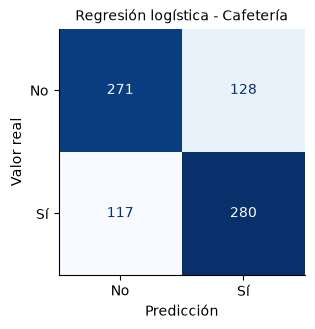

In [18]:
evaluar_en_prueba(busqueda_rl_caf, "Cafetería", "Regresión logística")

Sobre el conjunto de prueba el modelo obtiene un F1 macro de 0,692, algo menor que el de la validación cruzada pero
dentro de lo esperado. El desempeño es muy parecido para las dos clases: el recall es de 0,679 para los rechazos y de
0,705 para las aceptaciones, lo que es coherente con que Cafetería esté balanceada. En la matriz de confusión los
errores se reparten de forma similar entre falsos positivos y falsos negativos. Un rendimiento cercano a 0,70 indica
que, con una frontera de decisión lineal, el modelo captura parte del patrón pero deja una proporción importante de
escenarios sin explicar.

#### Regresión logística - Restaurante(<20)

In [19]:
busqueda_rl_rest = buscar(pipeline_rl(), grilla_rl, "Restaurante(<20)")
resumen_busqueda(busqueda_rl_rest)

Mejores hiperparámetros: {'modelo__C': 1, 'modelo__l1_ratio': 0, 'modelo__solver': 'saga'}
F1 macro promedio en validación cruzada: 0.6585


,regularizacion,C,l1_ratio,solver,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,L2,10.0,0.0,newton-cg,0.6682,0.6585,0.0177,1
23,L1,10.0,1.0,saga,0.6682,0.6585,0.0177,1
22,L1,10.0,1.0,liblinear,0.6684,0.6585,0.0177,1
15,L2,10.0,0.0,saga,0.6682,0.6585,0.0177,1
14,L2,10.0,0.0,liblinear,0.6682,0.6585,0.0177,1
12,L2,10.0,0.0,lbfgs,0.6684,0.6585,0.0177,1
11,L2,1.0,0.0,saga,0.6679,0.6585,0.0177,1
27,Elastic net,10.0,0.5,saga,0.6683,0.6585,0.0177,1


En Restaurante(<20) el F1 macro de validación es de 0,659, menor que en Cafetería. De nuevo, varias combinaciones
empatan en el primer lugar, incluidas las tres regularizaciones y los cuatro solvers, y la búsqueda
se queda con una de ellas (L2, `C = 1`, `saga`). En este caso los mejores resultados aparecen con valores de `C` altos, es
decir, con una regularización débil, y la brecha entre entrenamiento (0,668) y validación (0,659) sigue siendo
pequeña.

               precision    recall  f1-score   support

No acepta (0)      0.602     0.383     0.468       162
   Acepta (1)      0.778     0.895     0.833       392

     accuracy                          0.745       554
    macro avg      0.690     0.639     0.650       554
 weighted avg      0.727     0.745     0.726       554



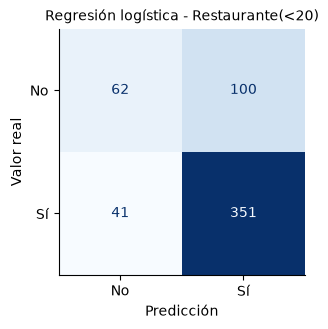

In [20]:
evaluar_en_prueba(busqueda_rl_rest, "Restaurante(<20)", "Regresión logística")

En el conjunto de prueba se observa el efecto del desbalance. El modelo reconoce el 89,5 % de las aceptaciones, pero
solo el 38,3 % de los rechazos: de los 162 conductores que no aceptaron el cupón, el modelo identifica correctamente
a 62. Por eso el F1 de la clase No (0,468) es mucho más bajo que el de la clase Sí (0,833), y el F1 macro queda en
0,650. Aunque la exactitud es de 0,745, este valor está apenas por encima del 70,8 % que se obtendría prediciendo
siempre Sí, lo que confirma que la accuracy no es una buena métrica en este caso. El bajo recall de la clase
minoritaria es justamente lo que se evaluará en la actividad 6 al aplicar una técnica de balanceo.

### Modelos de árboles de decisión

Un árbol de decisión clasifica los escenarios mediante una secuencia de preguntas sobre las variables, eligiendo en
cada nodo la división que deja los grupos resultantes lo más puros posible. A diferencia de la regresión logística, no
requiere escalar las variables, ya que cada división compara una variable con un umbral; por eso el pipeline usa el
preprocesamiento sin escalado.

El principal riesgo de un árbol es el sobreajuste: si crece sin límites, puede memorizar los datos de entrenamiento.
Por eso la búsqueda explora los hiperparámetros que controlan su complejidad. La profundidad máxima limita el número
de preguntas consecutivas, y el número mínimo de muestras por hoja impide crear hojas con muy pocos escenarios. Además
se explora el criterio de división: `gini` (impureza de Gini) y `entropy` o `log_loss` (ganancia de información).

In [21]:
grilla_arbol = {
    "modelo__max_depth": [3, 5, 7, 10, 15, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50],
    "modelo__criterion": ["gini", "entropy", "log_loss"],
}


def pipeline_arbol():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", DecisionTreeClassifier(random_state=SEED)),
    ])

#### Árbol de decisión - Cafetería

In [22]:
busqueda_arbol_caf = buscar(pipeline_arbol(), grilla_arbol, "Cafetería")
resumen_busqueda(busqueda_arbol_caf)

Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50}
F1 macro promedio en validación cruzada: 0.7121


,criterion,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
9,gini,5,50,0.7236,0.7121,0.0164,1
39,entropy,5,50,0.7234,0.7102,0.0165,2
69,log_loss,5,50,0.7234,0.7102,0.0165,2
66,log_loss,5,5,0.7274,0.7071,0.0137,4
36,entropy,5,5,0.7274,0.7071,0.0137,4
68,log_loss,5,20,0.7251,0.7068,0.0160,6
38,entropy,5,20,0.7251,0.7068,0.0160,6
65,log_loss,5,1,0.7278,0.7068,0.0117,8


El mejor árbol para Cafetería usa el criterio de Gini, una profundidad máxima de 5 y un mínimo de 50 escenarios por
hoja, con un F1 macro de validación de 0,712. Las mejores combinaciones de la tabla coinciden en una profundidad de 5,
lo que indica que árboles más profundos empiezan a sobreajustar. La restricción de 50 muestras por hoja también ayuda
a que el árbol no aprenda reglas basadas en muy pocos casos, y por eso el F1 de entrenamiento (0,724) se mantiene
cerca del de validación. Los criterios `entropy` y `log_loss` producen exactamente los mismos resultados porque en
scikit-learn ambos calculan la ganancia de información con la misma fórmula.

               precision    recall  f1-score   support

No acepta (0)      0.714     0.644     0.677       399
   Acepta (1)      0.674     0.741     0.706       397

     accuracy                          0.692       796
    macro avg      0.694     0.692     0.692       796
 weighted avg      0.694     0.692     0.692       796



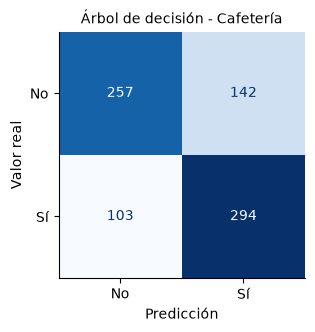

In [23]:
evaluar_en_prueba(busqueda_arbol_caf, "Cafetería", "Árbol de decisión")

En el conjunto de prueba el árbol logra un F1 macro de 0,692, igual al de la regresión logística. La diferencia está
en cómo se distribuyen los errores: el árbol tiene un recall algo mayor para las aceptaciones (0,741) y algo menor
para los rechazos (0,644). Que dos algoritmos tan distintos obtengan el mismo rendimiento sugiere que el límite no
está en el modelo sino en la información disponible en las variables.

#### Árbol de decisión - Restaurante(<20)

Pendiente.

### Modelos de Random Forest

Random Forest combina varios árboles entrenados con remuestreo de los escenarios y subconjuntos aleatorios de
variables. Al combinar sus predicciones puede capturar interacciones y reducir la variabilidad de un árbol individual.
Se reutiliza el preprocesamiento definido anteriormente sin escalado, porque los árboles dividen por umbrales.

La búsqueda explora el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el mínimo de muestras
por hoja (`min_samples_leaf`). Se mantienen las mismas particiones y la validación cruzada estratificada de diez
pliegues, seleccionando por F1 macro con la función `buscar`. El puntaje de prueba se usa únicamente para evaluar.


In [24]:
from sklearn.ensemble import RandomForestClassifier

grilla_rf = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [6, 12, None],
    "modelo__min_samples_leaf": [1, 5, 20],
}


def pipeline_rf():
    return Pipeline([
        ("preprocesamiento", crear_preprocesador()),
        ("modelo", RandomForestClassifier(random_state=SEED, n_jobs=1)),
    ])


#### Random Forest - Cafetería

Se entrena con los escenarios de Cafetería. La tabla permite comparar F1 macro en entrenamiento y validación para
examinar sobreajuste; los mejores hiperparámetros se eligen sin usar el conjunto de prueba.


In [25]:
busqueda_rf_caf = buscar(pipeline_rf(), grilla_rf, "Cafetería")
resumen_busqueda(busqueda_rf_caf)


Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 macro promedio en validación cruzada: 0.7677


,max_depth,min_samples_leaf,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,None,1,200,0.9992,0.7677,0.0177,1
12,None,1,100,0.9992,0.7645,0.0143,2
7,12,1,200,0.9454,0.7490,0.0261,3
6,12,1,100,0.9427,0.7487,0.0277,4
9,12,5,200,0.8201,0.7308,0.0199,5
8,12,5,100,0.8195,0.7305,0.0217,6
15,None,5,200,0.8370,0.7301,0.0204,7
14,None,5,100,0.8355,0.7286,0.0198,8


               precision    recall  f1-score   support

No acepta (0)      0.779     0.777     0.778       399
   Acepta (1)      0.776     0.778     0.777       397

     accuracy                          0.778       796
    macro avg      0.778     0.778     0.778       796
 weighted avg      0.778     0.778     0.778       796



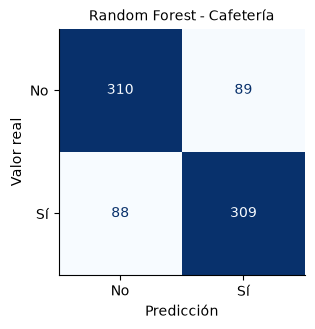

In [26]:
evaluar_en_prueba(busqueda_rf_caf, "Cafetería", "Random Forest")


#### Random Forest - Restaurante(<20)

Se ajusta un bosque independiente para Restaurante(<20), con la misma grilla y métrica de selección. Además del F1
macro, se debe revisar el recall de No, la clase minoritaria. Esta búsqueda corresponde al modelo sin balanceo.


In [27]:
busqueda_rf_rest = buscar(pipeline_rf(), grilla_rf, "Restaurante(<20)")
resumen_busqueda(busqueda_rf_rest)


Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 macro promedio en validación cruzada: 0.6987


,max_depth,min_samples_leaf,n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,None,1,200,0.9990,0.6987,0.0173,1
12,None,1,100,0.9990,0.6959,0.0195,2
6,12,1,100,0.8927,0.6796,0.0162,3
7,12,1,200,0.8953,0.6778,0.0223,4
9,12,5,200,0.7210,0.6618,0.0243,5
14,None,5,100,0.7258,0.6598,0.0239,6
8,12,5,100,0.7212,0.6586,0.0251,7
15,None,5,200,0.7257,0.6572,0.0226,8


               precision    recall  f1-score   support

No acepta (0)      0.681     0.395     0.500       162
   Acepta (1)      0.787     0.923     0.850       392

     accuracy                          0.769       554
    macro avg      0.734     0.659     0.675       554
 weighted avg      0.756     0.769     0.747       554



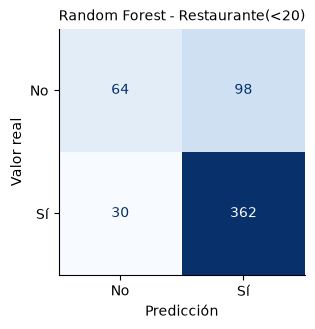

In [28]:
evaluar_en_prueba(busqueda_rf_rest, "Restaurante(<20)", "Random Forest")


Las evaluaciones agregan los dos bosques a `resultados_prueba`, por lo que aparecerán al ejecutar la tabla de la
sección siguiente. Si se repite una celda de evaluación, la función existente agrega otra fila; para reconstruir la
tabla sin repeticiones, ejecutar desde la celda que inicializa `resultados_prueba = []` y repetir las evaluaciones.


### Resultados parciales sobre el conjunto de prueba

In [29]:
pd.DataFrame(resultados_prueba).round(3)

,cupón,algoritmo,precisión No,recall No,F1 No,precisión Sí,recall Sí,F1 Sí,F1 macro
0,Cafetería,Regresión logística,0.698,0.679,0.689,0.686,0.705,0.696,0.692
1,Restaurante(<20),Regresión logística,0.602,0.383,0.468,0.778,0.895,0.833,0.650
2,Cafetería,Árbol de decisión,0.714,0.644,0.677,0.674,0.741,0.706,0.692
3,Cafetería,Random Forest,0.779,0.777,0.778,0.776,0.778,0.777,0.778
4,Restaurante(<20),Random Forest,0.681,0.395,0.500,0.787,0.923,0.850,0.675


En resumen, para Cafetería la regresión logística y el árbol de decisión tienen el mismo F1 macro en prueba (0,692),
con errores repartidos de forma equilibrada entre las dos clases. Para Restaurante(<20) la regresión logística
obtiene un F1 macro menor (0,650) y no logra identificar bien los rechazos, con un recall de la clase No de 38,3 %. Esta
tabla se completará con el árbol de decisión de Restaurante(<20) y con los modelos de Random Forest de la actividad 5
para construir la comparación final de la actividad 7.

## Análisis de resultados

En esta sección se responden las preguntas de análisis que ya pueden sustentarse con la exploración y los modelos
construidos hasta el momento. Las preguntas sobre las variables más relevantes, el balanceo de clases y la
interpretación de reglas se responderán al completar las actividades 5, 6 y 8.

### ¿Existen variables que podrían ser redundantes o poco informativas?

Sí. La exploración identificó tres columnas que no aportan información y que por eso se eliminaron en la preparación:
`tiempo_cupon_mayor_5min`, que es constante; `direccion_opuesta`, que es exactamente el complemento de
`misma_direccion`; y `vehiculo`, que está vacía en el 99,1 % de los escenarios.

Además, hay variables que no son redundantes del todo pero sí están muy relacionadas entre sí, por lo que su aporte
se solapa. El clima determina la temperatura cuando llueve o nieva, y el destino y la hora están ligados por el diseño
de la encuesta (por ejemplo, el destino Trabajo solo aparece a las 7:00 a.m.). Las variables de tiempo de viaje
mayor a 15 y a 25 minutos están anidadas. En estos casos se conservaron ambas variables porque cada una aporta algo
de información propia, pero su efecto individual es difícil de separar.

Por último, algunas variables parecen poco informativas para la aceptación. El género casi no cambia la tasa de
aceptación (49 % frente a 51 % en Cafetería), y otras variables demográficas muestran diferencias pequeñas frente a
las del contexto del viaje. También es probable que los hábitos de consumo de otros tipos de lugar (por ejemplo, la
frecuencia de visita a bares para el cupón de Cafetería) aporten poco; esto se verificará con la importancia de
variables de la actividad 8.

### ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué se atribuye esa diferencia?

Sí. Con la regresión logística, el F1 macro en el conjunto de prueba es de 0,692 en Cafetería y de 0,650 en
Restaurante(<20), y en la validación cruzada la diferencia es similar (0,715 frente a 0,659). Pero la diferencia más
importante está en el comportamiento: en Cafetería los errores se reparten de forma equilibrada entre las dos clases,
con un recall cercano a 0,70 en ambas, mientras que en Restaurante el modelo reconoce el 89,5 % de las aceptaciones y
solo el 38,3 % de los rechazos.

Esta diferencia se puede atribuir a tres factores. El primero es el desbalance de clases: en Restaurante el 70,7 % de
los escenarios son aceptaciones, por lo que el modelo tiende a favorecer la clase mayoritaria, ya que equivocarse con
los rechazos tiene un menor peso durante el entrenamiento. El segundo es la cantidad de datos: Restaurante tiene
2.769 escenarios frente a 3.979 de Cafetería, y solo 814 rechazos de los que aprender, lo que también explica la
mayor variación entre particiones. El tercero es que las variables separan mejor las clases en Cafetería. En la
exploración, el hábito de visitar cafeterías marca una diferencia muy grande en la aceptación (19 % para quienes
nunca van frente a 65 %–69 % para quienes van al menos una vez al mes), mientras que el hábito equivalente en
Restaurante tiene un efecto mucho menor (56 % frente a 67 %–76 %). En Restaurante la aceptación es alta en casi todos
los escenarios, por lo que los rechazos dependen de factores más difíciles de capturar con las variables disponibles.

### ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

El modelo se integraría como un servicio que recibe la información de un escenario y devuelve la probabilidad de que
el conductor acepte cada cupón. Cuando la aplicación detecta un establecimiento cercano a la ruta, construye el
escenario a partir de los datos que ya conoce: el destino y la hora del trayecto, el clima (obtenido de un servicio
meteorológico), el tiempo de desvío hasta el establecimiento, si queda en la misma dirección y los hábitos de consumo
registrados en el perfil del conductor. Como el preprocesamiento está dentro del pipeline, el modelo puede recibir el
escenario en el mismo formato de los datos originales, sin pasos adicionales.

Con la probabilidad estimada para cada tipo de cupón, la aplicación decide si muestra una oferta y cuál. Una regla
simple es mostrar el cupón con mayor probabilidad solo si supera un umbral. Ese umbral no tiene por qué ser 0,5: se
puede ajustar según lo que le cueste más a Ruta Alpes, ya sea molestar al conductor con una notificación irrelevante
o perder una oportunidad de venta. Los modelos de regresión logística y de árboles son muy rápidos al predecir, por lo
que la respuesta puede darse en tiempo real.

Por último, la aplicación debería registrar si el conductor acepta o no cada cupón mostrado, para medir el desempeño
real del modelo y volver a entrenarlo periódicamente. También es importante mostrar las notificaciones en momentos
seguros, por ejemplo cuando el vehículo está detenido, para no distraer al conductor.

### ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

La primera limitación es el propio desempeño de los modelos: con un F1 macro cercano a 0,69 en Cafetería y a 0,65 en
Restaurante, el sistema se equivocaría en una proporción importante de los casos. En Restaurante, además, el modelo
identifica muy pocos de los escenarios en los que el conductor rechazaría el cupón, por lo que seguiría enviando
muchas notificaciones irrelevantes, que es justo el problema que la empresa quiere resolver.

La segunda es que el modelo aprende correlaciones, no causas. Que un grupo de edad o de ingreso acepte más cupones en
los datos no significa que su perfil sea la razón de la aceptación; puede deberse a otras variables relacionadas, como
el destino o los hábitos de consumo. Además, la exploración mostró que el contexto del viaje (la distancia, la
vigencia del cupón o tener un lugar urgente al que llegar) se relaciona más con la aceptación que las variables
demográficas, por lo que basar la decisión en el perfil aporta poco y añade riesgos.

La tercera es la generalización. Algunos grupos tienen muy pocos casos en los datos (por ejemplo, 130 escenarios de
personas viudas y varias ocupaciones con menos de 50), por lo que las predicciones para ellos son poco confiables.
Asimismo, el perfil de un conductor es estático, mientras que sus preferencias pueden cambiar, y un sistema que solo
muestra cupones a quienes predice que los aceptarán deja de aprender de los demás, reforzando sus propias decisiones.
Por último, el uso de datos demográficos para personalizar ofertas requiere el consentimiento de los usuarios y
cumplir con la regulación de protección de datos personales.

### ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones?

En los datos se pueden identificar varias fuentes de sesgo. La primera es un sesgo de selección: según la descripción
del conjunto original, los datos provienen de una encuesta respondida en línea, por lo que los participantes no
necesariamente representan a todos los conductores de la aplicación. La segunda es un sesgo de respuesta, ya que los
escenarios son hipotéticos y la etiqueta indica si la persona dice que aceptaría el cupón, lo cual puede diferir de
su comportamiento real. La tercera es un sesgo de medición, porque variables como los hábitos de consumo o el ingreso
son autorreportadas y se registran en rangos amplios. Por último, hay un sesgo de representación: grupos como los
menores de 21 años, las personas viudas o algunas ocupaciones tienen pocos casos, y el modelo aprende menos de ellos.

En el proceso de modelado también puede introducirse sesgo. Las métricas globales, como el F1 macro, pueden ocultar
que el modelo funciona peor para ciertos grupos, y además variables como el ingreso, la ocupación o la edad pueden
actuar como sustitutos de otras características sensibles aunque no se incluyan de forma explícita. Si el modelo
aprende que un grupo acepta menos cupones, ese grupo recibirá menos ofertas y la diferencia se reforzará con el
tiempo, aunque se deba al contexto en que se recogieron los datos y no a una preferencia real.

En el caso de los cupones, el efecto de estos sesgos es que algunos grupos podrían recibir menos descuentos que
otros solo por su perfil demográfico. Si la misma lógica se usara para fijar precios dinámicos, las implicaciones
serían más graves: el sistema podría cobrar más a ciertos grupos según su edad, género o nivel de ingreso, lo que
sería una forma de discriminación difícil de detectar para los usuarios y, en muchos casos, contraria a la ley. Por
eso, antes de usar estas variables convendría evaluar el desempeño del modelo por grupos, comparar su rendimiento
con y sin las variables demográficas, y ser transparentes con los usuarios sobre qué información se usa para
personalizar las ofertas.